# Tugas Besar IoT — Bagian 2: Fitur Edge, Label Multi-Horizon, dan Model Early Warning

Lanjutan dari Bagian 1 (audit + digital twin). Isi notebook:
1. **Setup**: bekerja di folder repo lokal, atau otomatis `git clone` repo GitHub di Colab/laptop baru.
2. **Data**: memakai `outputs/sim_ponds.csv.gz` dari Bagian 1; kalau belum ada, simulasi dijalankan ulang (seed sama → data identik).
3. **Fase 3 – Fitur & label**: 46 fitur yang bisa dihitung di ESP32 (buffer 72 jam) + label kematian berlebih 6/12/24 jam.
4. **Fase 4 – Model**: baseline aturan, regresi logistik, Random Forest, LightGBM dengan **split per kolam + waktu** (bebas leakage).
5. **RQ2 – Inflasi metrik**: split acak vs split per kolam vs split per kolam + waktu.
6. **Figur & tabel** untuk paper.

> Waktu jalan penuh ±15–20 menit di CPU 2 core (Colab gratis). Set `QUICK = True` untuk uji cepat (±4 menit).

In [1]:
import os, sys, subprocess
REPO_URL = "https://github.com/USERNAME/tilapia-aiot.git"   # ganti USERNAME setelah repo dibuat

# cari root repo (folder yang berisi src/)
ROOT = next((p for p in [".", "..", "tilapia-aiot"] if os.path.isdir(os.path.join(p, "src"))), None)
if ROOT is None:                                  # Colab / laptop baru → clone dari GitHub
    subprocess.run(["git", "clone", REPO_URL], check=True); ROOT = "tilapia-aiot"
ROOT = os.path.abspath(ROOT); os.chdir(ROOT); sys.path.insert(0, os.path.join(ROOT, "src"))
print("Root repo:", ROOT)

Root repo: C:\Users\risma\OneDrive\Documents\SEMESTER 7\IOT\tilapia-aiot


In [2]:
%pip install -q lightgbm scikit-learn pandas numpy matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: C:\Users\risma\OneDrive\Documents\SEMESTER 7\IOT\tilapia-aiot\.venv\Scripts\python.exe -m pip install --upgrade pip


In [3]:
import json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from simulator import simulate_pond, PARAMS
from features import clean, make_features, make_labels, HORIZONS, THR
from modeling import evaluate, make_model, downsample, best_f1_threshold, CUT_TEST, CUT_VAL

QUICK = False                       # True = 3 fold & 1 horizon tambahan (untuk uji cepat)
N_SPLITS = 3 if QUICK else 5
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data simulasi (dari Bagian 1, atau dibuat ulang)

In [4]:
SIM = f"{OUT}/sim_ponds.csv.gz"
if os.path.exists(SIM):
    d = pd.read_csv(SIM, parse_dates=["datetime"])
else:
    print("File Bagian 1 tidak ditemukan → menjalankan simulasi ulang (200 kolam, seed 42) ...")
    rng = np.random.default_rng(42)
    d = pd.concat([simulate_pond(i, rng, PARAMS) for i in range(200)], ignore_index=True)
d = d.sort_values(["pond_id", "datetime"]).reset_index(drop=True)
print(d.shape, "| kolam:", d.pond_id.nunique(), "|", d.datetime.min(), "→", d.datetime.max())

(873600, 24) | kolam: 200 | 2024-01-01 00:00:00 → 2024-06-30 23:00:00


## 2. Fase 3 — Preprocessing edge, fitur, dan label
**Preprocessing (dijalankan di node IoT):** buang nilai di luar rentang fisik (mis. kode error sensor), filter lonjakan terhadap median 5 jam, isi data hilang maksimal 3 jam (*forward-fill*).

**Fitur (hanya dari 72 jam terakhir bacaan sensor + status aerator):** nilai sekarang, lag 1–24 jam, selisih DO, rata-rata/min/maks/std bergulir DO (6/24/72 jam), tren puncak sore & lembah fajar DO, jumlah jam DO < 4 dan < 2 mg/L, % saturasi DO (dihitung dari suhu), statistik suhu/pH/turbiditas 24 jam, fraksi aerator menyala, jumlah data hilang.
Kolom `true_*`, `alive`, `deaths`, dan `hazard` **tidak pernah** dipakai sebagai fitur.

**Label:** `y{H} = 1` jika ikan yang mati dalam H jam ke depan > 0,5% stok (≈ 4× kematian latar harian).

In [5]:
t0 = time.time()
c = clean(d); X = make_features(c); Y = make_labels(d)
meta = d[["pond_id", "datetime", "alive", "deaths", "true_do_mgl", "has_aerator"]].copy()
print(f"Fitur: {X.shape[1]} kolom | waktu {time.time()-t0:.1f} s")
print("Prevalensi label:", Y.mean().round(4).to_dict())
X.describe().T[["mean", "min", "max"]].round(2).head(12)

Fitur: 46 kolom | waktu 3.1 s
Prevalensi label: {'y6': 0.0045, 'y12': 0.0079, 'y24': 0.0167}


,mean,min,max
hour_sin,-0.00,-1.00,1.00
hour_cos,-0.00,-1.00,1.00
T,27.47,22.99,34.31
DO,6.54,0.00,22.51
pH,7.87,6.38,9.54
turb,6.65,0.00,68.82
DO_lag1,6.54,0.00,22.51
DO_lag3,6.54,0.00,22.51
DO_lag6,6.54,0.00,22.51
DO_lag12,6.54,0.00,22.51


## 3. Fase 4 — Protokol evaluasi bebas leakage
- **Split per kolam (GroupKFold, 5 fold):** kolam yang diuji tidak pernah dilihat saat training.
- **Split waktu:** training Jan–Apr, pengujian Mei–Jun.
- **Threshold alarm** dipilih memaksimalkan F1 di **April kolam training** (model dilatih Jan–Mar) → tidak ada informasi data uji yang bocor.
- **Metrik:** PR-AUC (utama, karena kelas positif langka), ROC-AUC, precision/recall/F1 pada threshold, **event recall** (kejadian yang didahului alarm ≤ 48 jam sebelum onset kematian), **median lead time**, dan **jam alarm palsu per kolam-bulan**.

In [6]:
horizons = (24,) if QUICK else HORIZONS
res = []
for H in horizons:
    t0 = time.time()
    res.append(evaluate(X, Y, meta, H, n_splits=N_SPLITS, protocol="pond_time"))
    print(f"H={H} selesai ({time.time()-t0:.0f} s)")
res = pd.concat(res); res.to_csv(f"{OUT}/results_pond_time.csv", index=False)
cols = ["pr_auc", "roc_auc", "precision", "recall", "f1", "event_recall", "median_lead_h", "false_alarm_h_per_pond_month"]
summary = res.groupby(["horizon", "model"])[cols].agg(["mean", "std"]).round(3)
summary

H=6 selesai (84 s)


H=12 selesai (96 s)


H=24 selesai (109 s)


pr_auc        roc_auc        precision        recall            f1        event_recall        median_lead_h         false_alarm_h_per_pond_month       
                 mean    std    mean    std      mean    std   mean    std   mean    std         mean    std          mean     std                         mean    std
horizon model                                                                                                                                                         
6       lgbm    0.817  0.072   0.981  0.025     0.799  0.073  0.713  0.105  0.747  0.063        0.729  0.083          17.5  12.942                        0.200  0.098
        logreg  0.705  0.098   0.985  0.020     0.689  0.068  0.663  0.117  0.671  0.079        0.684  0.091          21.0  16.804                        0.345  0.167
        rf      0.739  0.075   0.989  0.016     0.710  0.059  0.634  0.087  0.668  0.066        0.723  0.125          15.9   7.797                        0.283  0.144
        rule    0.181  0.058   0.974  0.024     0.223  0.045  0.460  0.120  0.297  0.058        0.315  0.153          33.3  15.991                        0.802  0.735
12      lgbm    0.727  0.031   0.975  0.019     0.678  0.081  0.695  0.089  0.678  0.023        0.795  0.095          17.1   7.773                        0.772  0.629
        logreg  0.586  0.063   0.969  0.020     0.638  0.112  0.562  0.059  0.593  0.059        0.634  0.097          18.1  11.360                        0.978  0.467
        rf      0.652  0.026   0.983  0.014     0.635  0.094  0.610  0.087  0.613  0.023        0.701  0.069          18.5   9.533                        0.712  0.515
        rule    0.214  0.091   0.940  0.035     0.231  0.073  0.461  0.056  0.303  0.070        0.410  0.131          28.9  14.993                        1.642  1.115
24      lgbm    0.541  0.113   0.952  0.013     0.522  0.141  0.540  0.115  0.520  0.096        0.745  0.139          34.7   6.130                        2.320  0.484
        logreg  0.475  0.112   0.951  0.019     0.560  0.154  0.423  0.109  0.475  0.104        0.571  0.134          40.5   6.892                        1.150  0.541
        rf      0.537  0.126   0.964  0.010     0.570  0.126  0.473  0.137  0.507  0.096        0.657  0.196          33.6  13.245                        1.427  0.583
        rule    0.252  0.113   0.863  0.049     0.338  0.143  0.370  0.087  0.349  0.123        0.487  0.114          47.8   0.447                        2.620  1.848

### 3.1 Tabel ringkas (mean ± sd antar fold) — siap untuk paper

In [7]:
def pm(g, c): return f"{g[c].mean():.3f} ± {g[c].std():.3f}"
tab = (res.groupby(["horizon", "model"])
          .apply(lambda g: pd.Series({"PR-AUC": pm(g, "pr_auc"), "ROC-AUC": pm(g, "roc_auc"), "F1": pm(g, "f1"),
                                      "Event recall": pm(g, "event_recall"), "Lead time (h)": f"{g.median_lead_h.median():.1f}",
                                      "False alarm h / pond-month": f"{g.false_alarm_h_per_pond_month.mean():.2f}",
                                      "Prevalence": f"{g.prevalence.mean():.4f}"}), include_groups=False))
tab.to_csv(f"{OUT}/table_main.csv"); tab

PR-AUC        ROC-AUC             F1   Event recall Lead time (h) False alarm h / pond-month Prevalence
horizon model                                                                                                                 
6       lgbm    0.817 ± 0.072  0.981 ± 0.025  0.747 ± 0.063  0.729 ± 0.083          21.0                       0.20     0.0044
        logreg  0.705 ± 0.098  0.985 ± 0.020  0.671 ± 0.079  0.684 ± 0.091          20.5                       0.34     0.0044
        rf      0.739 ± 0.075  0.989 ± 0.016  0.668 ± 0.066  0.723 ± 0.125          19.0                       0.28     0.0044
        rule    0.181 ± 0.058  0.974 ± 0.024  0.297 ± 0.058  0.315 ± 0.153          41.0                       0.80     0.0044
12      lgbm    0.727 ± 0.031  0.975 ± 0.019  0.678 ± 0.023  0.795 ± 0.095          18.0                       0.77     0.0080
        logreg  0.586 ± 0.063  0.969 ± 0.020  0.593 ± 0.059  0.634 ± 0.097          22.5                       0.98     0.0080
        rf      0.652 ± 0.026  0.983 ± 0.014  0.613 ± 0.023  0.701 ± 0.069          20.0                       0.71     0.0080
        rule    0.214 ± 0.091  0.940 ± 0.035  0.303 ± 0.070  0.410 ± 0.131          33.5                       1.64     0.0080
24      lgbm    0.541 ± 0.113  0.952 ± 0.013  0.520 ± 0.096  0.745 ± 0.139          34.5                       2.32     0.0169
        logreg  0.475 ± 0.112  0.951 ± 0.019  0.475 ± 0.104  0.571 ± 0.134          43.0                       1.15     0.0169
        rf      0.537 ± 0.126  0.964 ± 0.010  0.507 ± 0.096  0.657 ± 0.196          39.0                       1.43     0.0169
        rule    0.252 ± 0.113  0.863 ± 0.049  0.349 ± 0.123  0.487 ± 0.114          48.0                       2.62     0.0169

## 4. RQ2 — Seberapa besar metrik tergelembung jika split tidak benar?
Model yang sama (H = 24 jam) dievaluasi dengan tiga protokol: **acak** (baris diacak, kolam & waktu bocor), **per kolam** (waktu bocor), dan **per kolam + waktu** (protokol utama).

In [8]:
rq2 = [res[(res.horizon == 24) & (res.model != "rule")]]
rq2.append(evaluate(X, Y, meta, 24, models=("logreg", "rf", "lgbm"), protocol="random"))
rq2.append(evaluate(X, Y, meta, 24, models=("logreg", "rf", "lgbm"), protocol="pond", n_splits=N_SPLITS))
rq2 = pd.concat(rq2); rq2.to_csv(f"{OUT}/results_rq2.csv", index=False)
piv = rq2.groupby(["model", "protocol"]).pr_auc.mean().unstack()[["random", "pond", "pond_time"]]
piv["inflasi_random_vs_pond_time_%"] = 100 * (piv["random"] / piv["pond_time"] - 1)
piv.round(3)

protocol,random,pond,pond_time,inflasi_random_vs_pond_time_%
model,,,,
lgbm,0.855,0.668,0.541,58.216
logreg,0.569,0.553,0.475,19.807
rf,0.704,0.633,0.537,31.010


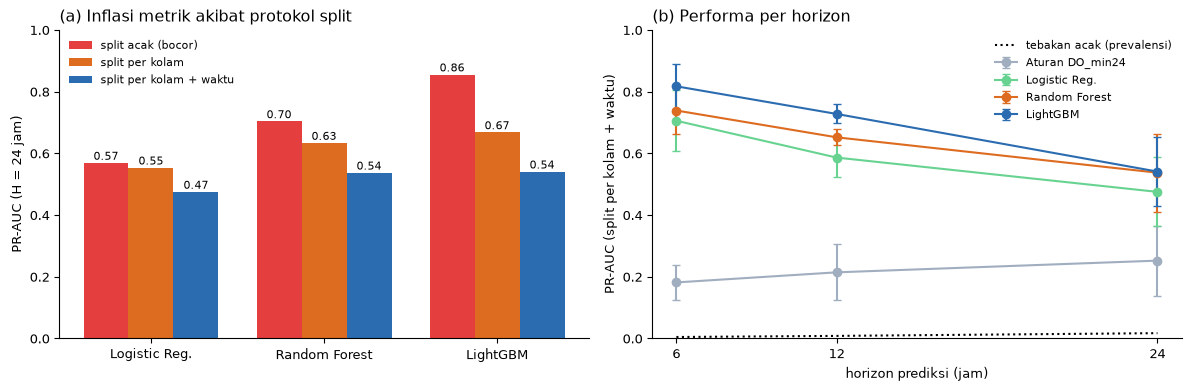

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
names = {"logreg": "Logistic Reg.", "rf": "Random Forest", "lgbm": "LightGBM", "rule": "Aturan DO_min24"}
cols_p = {"random": "#e53e3e", "pond": "#dd6b20", "pond_time": "#2b6cb0"}
lab_p = {"random": "split acak (bocor)", "pond": "split per kolam", "pond_time": "split per kolam + waktu"}
x = np.arange(3); w = 0.26
for i, p in enumerate(["random", "pond", "pond_time"]):
    v = piv[p].reindex(["logreg", "rf", "lgbm"])
    ax[0].bar(x + (i - 1) * w, v, w, color=cols_p[p], label=lab_p[p])
    for xi, vi in zip(x + (i - 1) * w, v): ax[0].text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=8)
ax[0].set_xticks(x, [names[m] for m in ["logreg", "rf", "lgbm"]]); ax[0].set_ylabel("PR-AUC (H = 24 jam)"); ax[0].set_ylim(0, 1)
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("(a) Inflasi metrik akibat protokol split", loc="left")

pr = res.groupby(["horizon", "model"]).pr_auc.agg(["mean", "std"]).reset_index()
for m, col in zip(["rule", "logreg", "rf", "lgbm"], ["#a0aec0", "#68d391", "#dd6b20", "#2b6cb0"]):
    s = pr[pr.model == m]
    ax[1].errorbar(s.horizon, s["mean"], yerr=s["std"], marker="o", capsize=3, color=col, label=names[m])
prev = res.groupby("horizon").prevalence.mean()
ax[1].plot(prev.index, prev.values, "k:", label="tebakan acak (prevalensi)")
ax[1].set_xticks(list(horizons)); ax[1].set_xlabel("horizon prediksi (jam)"); ax[1].set_ylabel("PR-AUC (split per kolam + waktu)")
ax[1].set_ylim(0, 1); ax[1].legend(frameon=False, fontsize=8); ax[1].set_title("(b) Performa per horizon", loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_models.png", dpi=160); plt.show()

## 5. Contoh early warning pada kolam yang tidak pernah dilihat model
Model LightGBM (H = 24 jam) dilatih pada kolam fold-0 periode Jan–Apr, lalu dijalankan seperti di perangkat pada kolam uji periode Mei–Jun.

threshold alarm = 0.764


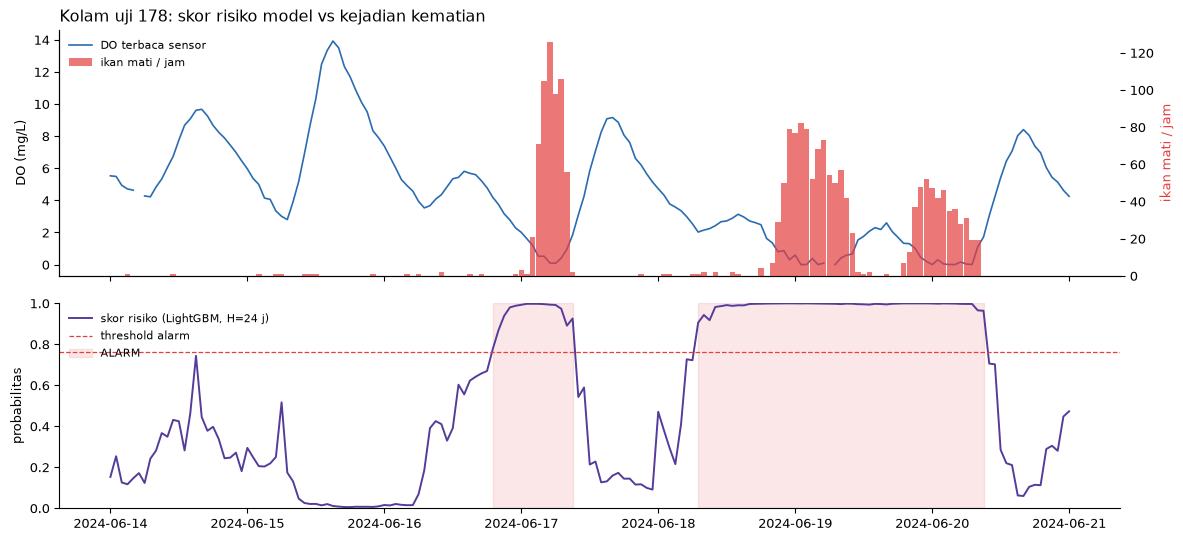

In [10]:
from sklearn.model_selection import GroupKFold
H = 24; y = np.nan_to_num(Y[f"y{H}"].values).astype(int)
ok = Y[f"y{H}"].notna().values & X["DO_lag24"].notna().values
idx = np.where(ok)[0]
trp, tep = next(GroupKFold(5).split(idx, groups=meta.pond_id.values[idx]))
tr, te = idx[trp], idx[tep]
tr_in = tr[meta.datetime.values[tr] < CUT_VAL]; va = tr[(meta.datetime.values[tr] >= CUT_VAL) & (meta.datetime.values[tr] < CUT_TEST)]
rng = np.random.default_rng(0)
s_in = downsample(tr_in, y, rng)
m_in = make_model("lgbm").fit(X.iloc[s_in], y[s_in])
thr = best_f1_threshold(y[va], m_in.predict_proba(X.iloc[va])[:, 1])
tr_full = tr[meta.datetime.values[tr] < CUT_TEST]; sub = downsample(tr_full, y, rng)
model = make_model("lgbm").fit(X.iloc[sub], y[sub])
te = te[meta.datetime.values[te] >= CUT_TEST]
score = pd.Series(model.predict_proba(X.iloc[te])[:, 1], index=te)
print(f"threshold alarm = {thr:.3f}")

tm = meta.loc[te].assign(score=score.values)
pid = tm.groupby("pond_id").deaths.sum().idxmax()
p = tm[tm.pond_id == pid]
worst = p.set_index("datetime").deaths.resample("D").sum().idxmax()
w = p[(p.datetime >= worst - pd.Timedelta(days=5)) & (p.datetime <= worst + pd.Timedelta(days=2))]
wd = d.loc[w.index]
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, height_ratios=[1.2, 1])
ax[0].plot(wd.datetime, wd.sensor_do_mgl, color="#2b6cb0", lw=1.2, label="DO terbaca sensor")
ax[0].set_ylabel("DO (mg/L)"); a2 = ax[0].twinx(); a2.bar(w.datetime, w.deaths, width=0.04, color="#e53e3e", alpha=0.7, label="ikan mati / jam")
a2.set_ylabel("ikan mati / jam", color="#e53e3e"); a2.spines["top"].set_visible(False)
h1, l1 = ax[0].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); ax[0].legend(h1 + h2, l1 + l2, frameon=False, fontsize=8, loc="upper left")
ax[0].set_title(f"Kolam uji {pid}: skor risiko model vs kejadian kematian", loc="left")
ax[1].plot(w.datetime, w.score, color="#553c9a", lw=1.4, label="skor risiko (LightGBM, H=24 j)")
ax[1].axhline(thr, ls="--", color="#e53e3e", lw=0.9, label="threshold alarm")
ax[1].fill_between(w.datetime, 0, 1, where=w.score >= thr, color="#e53e3e", alpha=0.12, transform=ax[1].get_xaxis_transform(), label="ALARM")
ax[1].set_ylabel("probabilitas"); ax[1].set_ylim(0, 1); ax[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_early_warning_example.png", dpi=160); plt.show()

## 6. Fitur paling berpengaruh (gain LightGBM) — analisis SHAP lengkap di Bagian 3

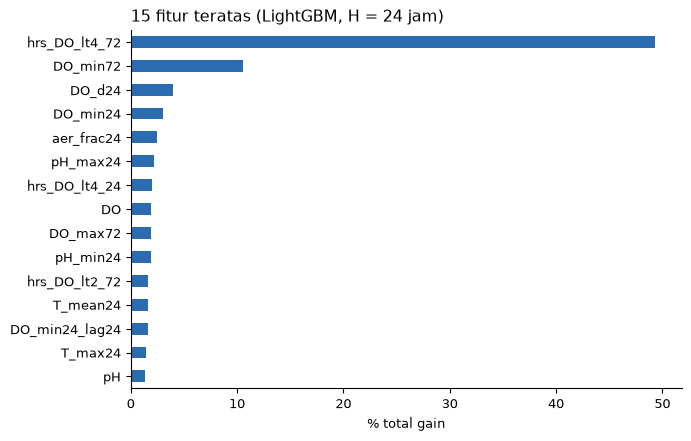

hrs_DO_lt4_72     49.33
DO_min72          10.52
DO_d24             3.94
DO_min24           3.06
aer_frac24         2.51
pH_max24           2.18
hrs_DO_lt4_24      1.99
DO                 1.95
DO_max72           1.92
pH_min24           1.89
hrs_DO_lt2_72      1.66
T_mean24           1.63
DO_min24_lag24     1.61
T_max24            1.44
pH                 1.38
dtype: float64

In [11]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=X.columns).sort_values(ascending=False)
imp = 100 * imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.head(15)[::-1].plot.barh(ax=ax, color="#2b6cb0"); ax.set_xlabel("% total gain")
ax.set_title("15 fitur teratas (LightGBM, H = 24 jam)", loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_feature_importance.png", dpi=160); plt.show()
imp.head(15).round(2)

## 7. Simpan ringkasan

In [12]:
summary_json = {
    "prevalence": Y.mean().round(4).to_dict(),
    "main_pr_auc": res.groupby(["horizon", "model"]).pr_auc.mean().round(3).unstack().to_dict(),
    "rq2_pr_auc_h24": piv.round(3).to_dict(),
    "top_features": imp.head(10).round(2).to_dict(),
}
json.dump(summary_json, open(f"{OUT}/part2_summary.json", "w"), indent=1, default=str)
summary_json

{'prevalence': {'y6': 0.0045, 'y12': 0.0079, 'y24': 0.0167},
 'main_pr_auc': {'lgbm': {6: 0.817, 12: 0.727, 24: 0.541},
  'logreg': {6: 0.705, 12: 0.586, 24: 0.475},
  'rf': {6: 0.739, 12: 0.652, 24: 0.537},
  'rule': {6: 0.181, 12: 0.214, 24: 0.252}},
 'rq2_pr_auc_h24': {'random': {'lgbm': 0.855, 'logreg': 0.569, 'rf': 0.704},
  'pond': {'lgbm': 0.668, 'logreg': 0.553, 'rf': 0.633},
  'pond_time': {'lgbm': 0.541, 'logreg': 0.475, 'rf': 0.537},
  'inflasi_random_vs_pond_time_%': {'lgbm': 58.216,
   'logreg': 19.807,
   'rf': 31.01}},
 'top_features': {'hrs_DO_lt4_72': 49.33,
  'DO_min72': 10.52,
  'DO_d24': 3.94,
  'DO_min24': 3.06,
  'aer_frac24': 2.51,
  'pH_max24': 2.18,
  'hrs_DO_lt4_24': 1.99,
  'DO': 1.95,
  'DO_max72': 1.92,
  'pH_min24': 1.89}}